In [2]:
!pip install mediapipe --quiet 
import mediapipe as mp
import cv2

# Initialize MediaPipe Hands
mp_hands = mp.solutions.hands
hands = mp_hands.Hands(static_image_mode=True, max_num_hands=1, min_detection_confidence=0.5)

def detect_and_crop_hand(image):
    # Convert to RGB
    if image.shape[-1] == 1:
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    results = hands.process(image_rgb)

    if results.multi_hand_landmarks:
        h, w, _ = image.shape
        x_min, y_min, x_max, y_max = w, h, 0, 0
        for lm in results.multi_hand_landmarks[0].landmark:
            x, y = int(lm.x * w), int(lm.y * h)
            x_min = min(x_min, x)
            y_min = min(y_min, y)
            x_max = max(x_max, x)
            y_max = max(y_max, y)

        pad = 20
        x_min = max(0, x_min - pad)
        y_min = max(0, y_min - pad)
        x_max = min(w, x_max + pad)
        y_max = min(h, y_max + pad)

        cropped = image[y_min:y_max, x_min:x_max]
        if cropped.size > 0:
            return cv2.resize(cropped, (64, 64))  # assuming 64x64 input for CNN

    return cv2.resize(image, (64, 64))  # fallback


/opt/conda/lib/python3.10/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()
W0000 00:00:1744812486.740333     132 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744812486.777434     132 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [3]:
# Import necessary libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, classification_report

# Specify dataset paths
train_path = '/kaggle/input/gujrati-signs-images/data/train'
test_path = '/kaggle/input/gujrati-signs-images/data/test'

# Define class labels
classes = {
    'ka': 0, 'kha': 1, 'ga': 2, 'gha': 3, 'cha': 4, 'chha': 5, 'ja': 6, 'za': 7, 'tta': 8, 'thha': 9,
    'dda': 10, 'dhha': 11, 'nna': 12, 'ta': 13, 'tha': 14, 'da': 15, 'dha': 16, 'na': 17, 'pa': 18,
    'fa': 19, 'ba': 20, 'bha': 21, 'ma': 22, 'ya': 23, 'ra': 24, 'la': 25, 'va': 26, 'sha': 27,
    'sh': 28, 'sa': 29, 'ha': 30, 'lla': 31, 'ksha': 32, 'gna': 33
}

# Load and preprocess images
X = []
Y = []

for cls in classes:
    class_path = os.path.join(train_path, cls)
    for img_name in os.listdir(class_path):
        img_path = os.path.join(class_path, img_name)
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)  # Load image in color (3 channels)
        img = cv2.resize(img, (64, 64))  # Resize to 64x64 pixels
        X.append(img)
        Y.append(classes[cls])

# Convert lists to numpy arrays
X = np.array(X)
Y = np.array(Y)

# Normalize data
X = X / 255.0  # Normalize pixel values to range [0, 1]

# One-hot encode labels
lb = LabelBinarizer()
Y = lb.fit_transform(Y)


In [4]:
# Split the data into training and testing sets
xtrain, xtest, ytrain, ytest = train_test_split(X, Y, test_size=0.3, random_state=42)


In [5]:
# Define the custom CNN model with adjusted architecture
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),  # This layer flattens the output from the convolutional layers
    Dense(128, activation='relu'),  # Adjusted number of neurons in the Dense layer
    Dropout(0.5),
    Dense(len(classes), activation='softmax')  # Output layer with the number of classes
])


/opt/conda/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

# Set up early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)


In [7]:
# Train the model
cnn_history = model.fit(
    xtrain, ytrain,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping]
)


Epoch 1/20


I0000 00:00:1744812654.273499     147 service.cc:145] XLA service 0x7d01f40057e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1744812654.273564     147 service.cc:153]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0


39/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0386 - loss: 3.5308 

I0000 00:00:1744812658.072345     147 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


75/75 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.0355 - loss: 3.5285 - val_accuracy: 0.0301 - val_loss: 3.5228
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0308 - loss: 3.5218 - val_accuracy: 0.0401 - val_loss: 3.5115
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0458 - loss: 3.5073 - val_accuracy: 0.0385 - val_loss: 3.4998
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0593 - loss: 3.4669 - val_accuracy: 0.0753 - val_loss: 3.4530
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0851 - loss: 3.4102 - val_accuracy: 0.0702 - val_loss: 3.4050
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1017 - loss: 3.3258 - val_accuracy: 0.1171 - val_loss: 3.3392
Epoch 7/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1238 - loss: 3.2704 - val_accuracy: 0.1237 - val_loss: 3.2730
Epoch 8/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1386 - loss: 3.1592 - val_accuracy: 0.1722 - val_loss: 3.1638
E

In [8]:
# Evaluate the model
train_loss, train_accuracy = model.evaluate(xtrain, ytrain)
test_loss, test_accuracy = model.evaluate(xtest, ytest)
print(f"CNN Training Accuracy: {train_accuracy}")
print(f"CNN Testing Accuracy: {test_accuracy}")

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7309 - loss: 1.2848
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5593 - loss: 1.8533
CNN Training Accuracy: 0.6996655464172363
CNN Testing Accuracy: 0.5756630301475525


In [12]:
# ✅ Save the model after training
model.save("sign_language_model_with_mediapipe.h5")
print("Model saved as sign_language_model_with_mediapipe.h5")


Model saved as sign_language_model_with_mediapipe.h5


Final Validation Accuracy: 55.35%


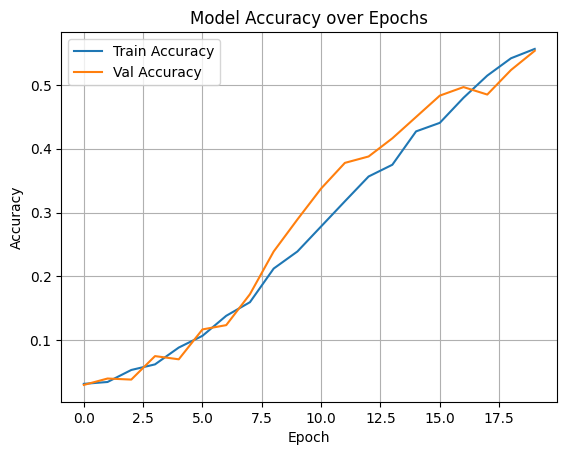

In [15]:
# ✅ Use final accuracy
final_accuracy = cnn_history.history['val_accuracy'][-1]
print(f"Final Validation Accuracy: {final_accuracy * 100:.2f}%")

# ✅ Plot accuracy over epochs
import matplotlib.pyplot as plt

plt.plot(cnn_history.history['accuracy'], label='Train Accuracy')
plt.plot(cnn_history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


In [9]:
# Predict on test data
y_pred = model.predict(xtest)
y_pred_classes = np.argmax(y_pred, axis=1)
ytest_classes = np.argmax(ytest, axis=1)

# Print the classification report
print("Classification Report:\n", classification_report(ytest_classes, y_pred_classes))


41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Classification Report:
               precision    recall  f1-score   support

           0       0.42      0.58      0.49        43
           1       1.00      0.77      0.87        48
           2       0.53      0.72      0.61        43
           3       0.48      0.72      0.57        43
           4       0.64      0.42      0.51        38
           5       0.53      0.82      0.65        38
           6       0.60      0.72      0.65        39
           7       0.52      0.65      0.58        37
           8       0.88      0.37      0.52        41
           9       0.68      0.44      0.54        43
          10       0.42      0.75      0.54        40
          11       0.83      0.78      0.81        51
          12       0.58      0.59      0.58        32
          13       0.65      0.68      0.67        38
          14       0.49      0.49      0.49        35
          15       0.64      0.64      0.64        33
          16      

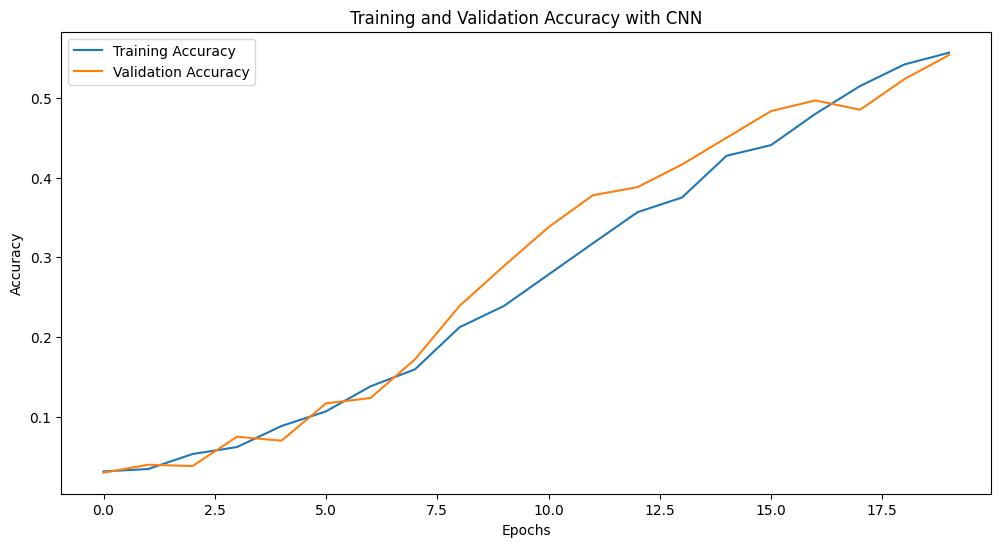

In [10]:
# Plot training history
plt.figure(figsize=(12, 6))
plt.plot(cnn_history.history['accuracy'], label='Training Accuracy')
plt.plot(cnn_history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy with CNN')
plt.legend()
plt.show()


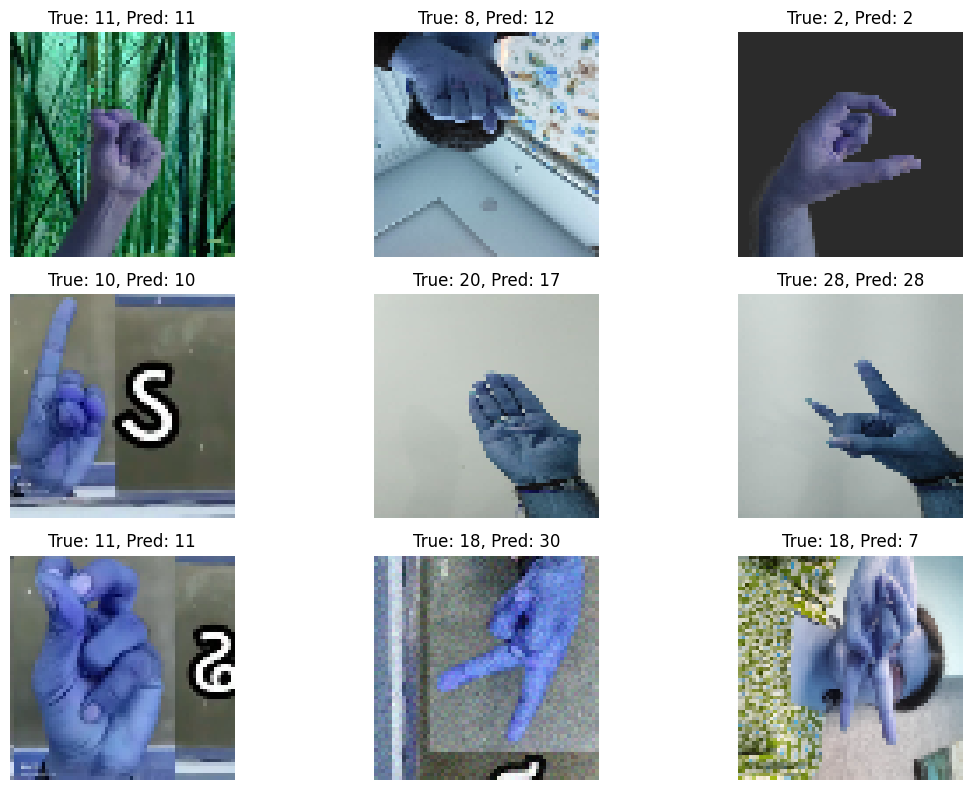

In [11]:
# Visualize some test predictions
plt.figure(figsize=(12, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(xtest[i])
    plt.title(f"True: {lb.classes_[ytest_classes[i]]}, Pred: {lb.classes_[y_pred_classes[i]]}")
    plt.axis('off')
plt.tight_layout()
plt.show()